<img src="../assets/ga-logo.png" style="float: left; margin: 20px; height: 55px">

# Hyperparameters, GridSearch, and Pipelines - Solution

---

### About
An introduction to optimizing machine learning models with grid search and pipelines in `scikit-learn`.

### Learning Objectives
- Describe what the terms hyperparameters, GridSearch, and pipeline mean.
- Apply `sklearn`'s `GridSearchCV` object.
- Use attributes of the GridSearch object.
- Describe the pitfalls of searching large hyperparameter spaces.
- Build pipelines.

### Notebook Guide

- Imports and Data Setup
- Data SetUp
- Grid Search
- Pipelines
- A Word of Caution on GridSearching
- Alternative: RandomSearchCV

![](https://snag.gy/aYcCt2.jpg)

# Imports and Data Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

In [2]:
abalone_colnames = [
    'sex', 'length', 'diameter', 'height', 'whole_weight',
    'shucked_weight', 'viscera_weight', 'shell_weight', 'rings'
]
ab = pd.read_csv('../data/abalone.data', names=abalone_colnames)
ab.head()

,sex,length,diameter,height,whole_weight,shucked_weight,viscera_weight,shell_weight,rings
0,M,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150,15
1,M,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070,7
2,F,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210,9
3,M,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155,10
4,I,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055,7


In [3]:
ab.shape

(4177, 9)

In [4]:
ab.isna().sum()

sex               0
length            0
diameter          0
height            0
whole_weight      0
shucked_weight    0
viscera_weight    0
shell_weight      0
rings             0
dtype: int64

### Let's Whiz Through the Boring Parts
Quickly so as to get to the fun parts, I'll:
* Create our `X` and `y`. We'll be doing a kNN, so can't use `sex`.
* Do a train-test split
* Scale our data

In [5]:
X = ab.drop(columns=['sex', 'rings'])
y = ab['rings']
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=2022)

sc = StandardScaler()
X_train_sc = sc.fit_transform(X_train)
X_test_sc = sc.transform(X_test)

# Grid Search
---
> _Friends don't let friends use Grid Search._

Up until now, we've tuned our tuning parameters either automatically using some `sklearn` tech, or via sloppy loops. `sklearn` gives us some fun tools for automating this process in many cases. Let's demonstrate with a simple kNN first.

In [6]:
knn = KNeighborsRegressor()

pgrid = {'n_neighbors': np.arange(1, 202, 5)}

gs = GridSearchCV(estimator=knn, param_grid=pgrid)

In [7]:
gs.fit(X_train_sc, y_train);

In [8]:
gs.best_params_

{'n_neighbors': 31}

In [9]:
gs.best_estimator_

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",31
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Uniform weights are used by default.See the following example for a demonstration of the impact ofdifferent weighting schemes on predictions::ref:`sphx_glr_auto_examples_neighbors_plot_regression.py`.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this isequivalent to using manhattan_distance (l1), and euclidean_distance(l2) for p = 2. For arbitrary p, minkowski_distance (l_p) is used.",2
,"metric metric: str, DistanceMetric object or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.If metric is a DistanceMetric object, it will be passed directly tothe underlying computation routines.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"effective_metric_ effective_metric_: str or callableThe distance metric to use. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'
"effective_metric_params_ effective_metric_params_: dictAdditional keyword arguments for the metric function. For most metricswill be same with `metric_params` parameter, but may also contain the`p` parameter value if the `effective_metric_` attribute is set to'minkowski'.",dict,{}


In [10]:
pd.DataFrame(gs.cv_results_).head()

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_n_neighbors,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
0,0.007317,0.007254,0.001142,0.001131,1,{'n_neighbors': 1},0.208134,0.143136,0.189533,0.212117,0.234357,0.197455,0.030673,41
1,0.000278,0.000556,0.005513,0.006800,6,{'n_neighbors': 6},0.462631,0.528564,0.490114,0.452478,0.525148,0.491787,0.031189,24
2,0.003043,0.002527,0.005081,0.001326,11,{'n_neighbors': 11},0.509811,0.542607,0.510713,0.489675,0.553135,0.521188,0.023288,9
3,0.002197,0.000742,0.004562,0.002300,16,{'n_neighbors': 16},0.522055,0.554505,0.519089,0.494522,0.558949,0.529824,0.023997,4
4,0.002837,0.002775,0.007141,0.003289,21,{'n_neighbors': 21},0.521562,0.551017,0.520809,0.491308,0.569272,0.530794,0.026958,3


In [11]:
df_gs = pd.DataFrame(gs.cv_results_)

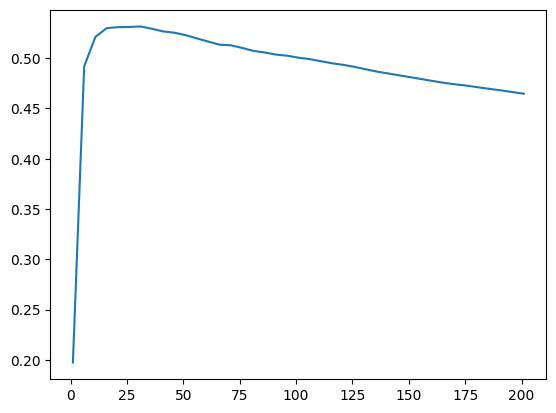

In [12]:
plt.plot(df_gs.param_n_neighbors, df_gs.mean_test_score);

This is cool!!! And we actually have `gs.best_estimator_` already fit as our optional model. But there's actually one more piece of efficiency `sklearn` can give us:

---

To the slides!

---

# Pipelines
---
Pipelines in `sklearn` allow you to combine several steps into one `estimator` or `transformer` object. That is, you can have pipelines of two forms:

* one or more transformers + one estimator
* one or more transformers (note this is the same as using a `ColumnTransformer` on all column

Note that one of your transformers in the first for could also just be a `ColumnTransformer`.

In [13]:
pipe = Pipeline([
    ('sc', StandardScaler()),
    ('knn', KNeighborsRegressor(n_neighbors=27))
])

In [14]:
pipe.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('sc', ...), ('knn', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](7,)","['length','diameter','height',...,'shucked_weight','viscera_weight', 'shell_weight']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,7
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [15]:
pipe.score(X_test, y_test)

0.5000410458159559

# Pipelines + Grid Search - All together, now!
You can, of course, use these all in conjunction. Let's try a new example with different data.

We'll use data on heart disease from a studen on men in Western Cape, South Africa. You can find a better description of the data [here](https://hastie.su.domains/ElemStatLearn/datasets/SAheart.info.txt).

In [16]:
heart = pd.read_csv('../data/SAheart.data')
heart['famhist'] = (heart['famhist'] == 'Present')*1 
heart.head()

,row.names,sbp,tobacco,ldl,adiposity,famhist,typea,obesity,alcohol,age,chd
0,1,160,12.00,5.73,23.11,1,49,25.30,97.20,52,1
1,2,144,0.01,4.41,28.61,0,55,28.87,2.06,63,1
2,3,118,0.08,3.48,32.28,1,52,29.14,3.81,46,0
3,4,170,7.50,6.41,38.03,1,51,31.99,24.26,58,1
4,5,134,13.60,3.50,27.78,1,60,25.99,57.34,49,1


In [17]:
X = heart.drop(columns=['row.names', 'chd'])
y = heart['chd']

In [18]:
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=2022)

In [19]:
X_train.shape

(346, 9)

In [20]:
# Warning! You could accidentally make too many pairs of
# parameters and your model could take an extremely long time
# to fit! Start small.
pgrid = {
    'lr__penalty': ['l1', 'l2'],
    'lr__C': np.logspace(-2, 0, 100)
}

StandardScaler
pipe = Pipeline([
    ('sc', StandardScaler()),
    ('lr', LogisticRegression(solver='liblinear'))
])

gs = GridSearchCV(pipe, param_grid=pgrid, n_jobs=8)

In [21]:
%%time

gs.fit(X_train, y_train)
None;

CPU times: total: 1.06 s
Wall time: 3.59 s


C:\Users\CharleyHanania\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\CharleyHanania\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


In [22]:
df_gs = pd.DataFrame(gs.cv_results_)

In [23]:
df_gs.shape

(200, 15)

In [24]:
y.mean()

0.3463203463203463

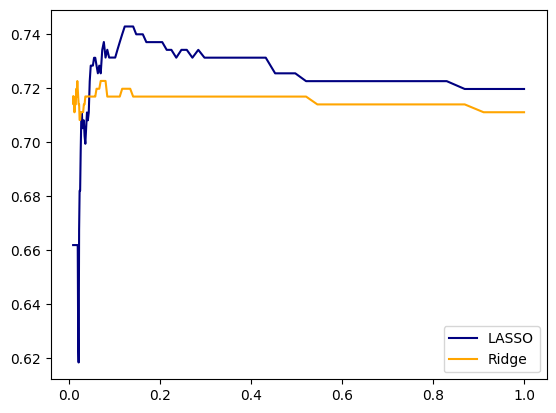

In [25]:
plt.plot(
    df_gs.loc[df_gs.param_lr__penalty == 'l1', 'param_lr__C'],
    df_gs.loc[df_gs.param_lr__penalty == 'l1', 'mean_test_score'],
    c='navy',
    label='LASSO'
)
plt.plot(
    df_gs.loc[df_gs.param_lr__penalty == 'l2', 'param_lr__C'],
    df_gs.loc[df_gs.param_lr__penalty == 'l2', 'mean_test_score'],
    c='orange',
    label='Ridge'
)
plt.legend(loc=4);

In [26]:
gs.best_params_

{'lr__C': 0.12328467394420665, 'lr__penalty': 'l1'}

# A Word of Caution on GridSearching

`sklearn` models often have many hyperparameters with many different possible values. It may be tempting to search over a wide variety of them. In general, this is not wise.

<details><summary>Why not?</summary>

- Remember that GridSearch searches over **all possible combinations of hyperparameters in the parameter dictionary!**

Imagine that we had this as our parameter dictionary:

```python
parameter_grid = {
    'n_neighbors': range(1, 151),
    'weights': ['uniform', 'distance', custom_function],
    'algorithm': ['ball_tree', 'kd_tree', 'brute', 'auto'],
    'leaf_size': range(1, 152),
    'metric': ['minkowski', 'euclidean'],
    'p': [1, 2]
}
```

**How many different combinations will need to be tested?**

| Parameter | Number of Chosen Values |
| --- | --- |
| **n_neighbors** | 150 |
| **weights** | 3 |
| **algorithm** | 4 |
| **leaf_size** | 151 |
| **metric** | 2 |
| **p** | 2 |
| <br>_150 \* 3 \* 4 \* 151 \* 2 \* 2 = n combinations_ <br><br>| _1,087,200_ |

If we select `cv = 5`, we would fit 1,087,200 models on five folds, meaning we fit 5,436,000 models!

If you're not careful, GridSearching can quickly scale out of hand computationally.

> **It is extremely important to understand what the hyperparameters do and think critically about what ranges are useful and relevant to your model!**
</details>

# Alternative: `RandomSearchCV`
**Random searching** (aka **stochastic searching**) is a much more recommended method for large parameter spaces. It choses tuning parameter combinations at random to "visit" more of the parameter space without doing an exhaustive search.

In [27]:
from sklearn.model_selection import RandomizedSearchCV

In [28]:
# RandomizedSearchCV()

## Interview Question

<details><summary>What is the difference between hyperparameters and statistical parameters?</summary>
    
- Statistical parameters are quantities that a model can learn or estimate. Examples include $\beta_0$ and $\beta_1$ in a linear model.
- Hyperparameters are quantities our model cannot learn, but affect the fit of our model. Examples include $k$ in $k$-nearest neighbors and $alpha$ in regularization.
</details>